[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/06_trees.ipynb)

*Machine Learning from Scratch · Notebook 6 of 10*

# Decision Trees

Models that ask a sequence of yes/no questions: impurity (Gini, entropy, MSE), finding the best split, growing and stopping, predictions, depth and leaves, feature importance, and overfitting.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A decision tree plays 20 Questions, choosing whichever question splits the data most cleanly.

**What interviewers really test here:** Gini vs entropy, overfitting, pruning and feature importance pitfalls.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. A model made of questions *(Basics)*
- [ ] 2. Impurity by hand *(Basics)*
- [ ] 3. Choosing a question: impurity *(Core)*
- [ ] 4. Growing, stopping and overfitting *(Core)*
- [ ] 5. Finding the best split, every candidate by hand *(Core)*
- [ ] 6. Regression trees by hand *(Core)*
- [ ] 7. Regression trees and feature importance *(Advanced)*
- [ ] 8. Pruning: cost-complexity by hand *(Advanced)*
- [ ] 9. Importance, instability and when to use trees *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### How trees are built (CART)

1. At a node with samples S, for every feature j and threshold t (midpoints of sorted unique values), split S into S\_L = {x\_j ≤ t} and S\_R.
2. Score = I(S) − (|S\_L|/|S|)·I(S\_L) − (|S\_R|/|S|)·I(S\_R), with impurity I = Gini, entropy or MSE.
3. Choose the best (j, t) — a **greedy**, locally optimal choice (finding the globally optimal tree is NP-hard).
4. Recurse until a stopping rule: pure node, max\_depth, min\_samples\_split/leaf, no impurity decrease, max\_leaf\_nodes (best-first).



Cost of training ≈ O(d · n log n · depth). sklearn implements CART (binary splits); ID3/C4.5 use entropy and multi-way splits.

### Impurity measures

| Measure | Formula | Max (2 classes) |
| --- | --- | --- |
| Gini | 1 − Σ pₖ² | 0.5 |
| Entropy | −Σ pₖ log₂ pₖ | 1 |
| Misclassification | 1 − max pₖ | 0.5 (not used for growing: not sensitive enough) |
| MSE / variance | (1/n)Σ(y − ȳ)² | regression |
| MAE, Poisson, Friedman MSE | regression variants |   |

### Strengths, weaknesses, regularisation

| Strengths | Weaknesses |
| --- | --- |
| interpretable rules; no scaling; mixed types; non-linear; interactions captured automatically; fast prediction | high variance / unstable; overfits when deep; axis-aligned steps; can't extrapolate; greedy splits; biased importances |



Pre-pruning: max\_depth, min\_samples\_leaf, min\_samples\_split, max\_leaf\_nodes, min\_impurity\_decrease. Post-pruning: minimal cost-complexity pruning, R\_α(T) = R(T) + α·|leaves|, choose α by CV (`cost_complexity_pruning_path`).

### Practical tuning guide

| Symptom | Change |
| --- | --- |
| Train accuracy near 100%, test much lower | lower max\_depth; raise min\_samples\_leaf; raise ccp\_alpha |
| Both low | allow more depth; add better features; switch to boosting |
| Rules are too hard to read | max\_depth of 3–5, or max\_leaf\_nodes |
| Results change with small data changes | use a random forest |
| Imbalanced classes | class\_weight="balanced" |

---
# Part 2: Lessons, step by step

## Lesson 1: A model made of questions

*Level: Basics*

A **decision tree** predicts by asking yes/no questions about the features, like a game of 20 questions: "Is income ≤ 40k? → Is age ≤ 30? → predict 'decline'".




- The top question is the **root**; the final answers are **leaves**.
- A classification leaf predicts the most common class of the training rows that reached it (and their shares as probabilities); a regression leaf predicts their average.
- The boundary is made of axis-parallel steps. No scaling needed, handles mixed feature types, and is easy to explain.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

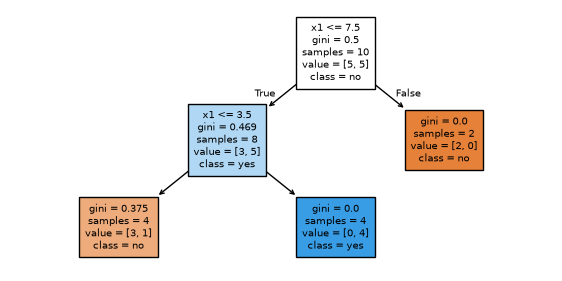

In [2]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
X3 = np.array([[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], dtype=float)
Y3 = np.array([0, 1, 0, 1, 0, 1, 1, 1, 0, 0])


def draw_tree():
    tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X3, Y3)
    fig, ax = plt.subplots(figsize=(7, 3.4))
    plot_tree(tree, feature_names=["x0", "x1"], class_names=["no", "yes"], filled=True, impurity=True, ax=ax, fontsize=7)


draw_tree()

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q4](#q4), [Q6](#q6), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 2: Impurity by hand

*Level: Basics*

A node has some mix of classes. Impurity puts a number on the mix.



#### Gini = 1 − Σ(share)²



You can read Gini as: pick two rows at random from the node; how often do their classes differ?



| Node | Shares | Calculation | Gini |
| --- | --- | --- | --- |
| 4 yes, 4 no | 0.5, 0.5 | 1 − 0.25 − 0.25 | 0.50 (most mixed) |
| 1 no, 4 yes | 0.2, 0.8 | 1 − 0.04 − 0.64 | 0.32 |
| 3 no, 0 yes | 1, 0 | 1 − 1 − 0 | 0 (pure) |



#### Entropy = −Σ share × log₂(share)



This measures surprise in bits: how many yes/no questions you'd need on average to identify the class.



| Node | Calculation | Entropy |
| --- | --- | --- |
| 4 yes, 4 no | −0.5·log₂0.5 − 0.5·log₂0.5 | 1.000 |
| 1 no, 4 yes | −0.2·log₂0.2 − 0.8·log₂0.8 | 0.722 |
| pure | −1·log₂1 | 0 |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

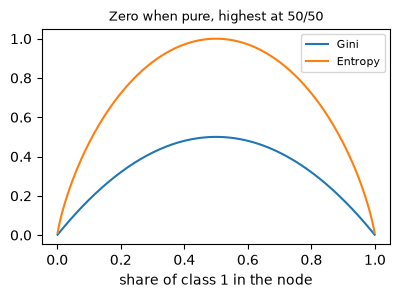

In [3]:
def impurity_curves():
    p = np.linspace(0.001, 0.999, 200)
    gini_values = 2 * p * (1 - p)
    entropy_values = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
    fig, ax = plt.subplots(figsize=(4.5, 2.8))
    ax.plot(p, gini_values, label="Gini")
    ax.plot(p, entropy_values, label="Entropy")
    ax.set_xlabel("share of class 1 in the node")
    ax.legend(fontsize=8)
    ax.set_title("Zero when pure, highest at 50/50", fontsize=9)


impurity_curves()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2). Try one now, or carry on and do them in Part 3.

## Lesson 3: Choosing a question: impurity

*Level: Core*

A good question splits the data into groups that are each as **pure** (single-class) as possible. Impurity measures how mixed a group is:



| Measure | Formula | Pure | 50/50 |
| --- | --- | --- | --- |
| **Gini** | 1 − Σpₖ² | 0 | 0.5 |
| **Entropy** | −Σpₖ log₂ pₖ | 0 | 1 |
| MSE (regression) | variance of the targets | 0 | — |



The algorithm tries **every feature** and **every threshold** (midpoints between neighbouring values) and picks the one with the largest **impurity decrease** = parent impurity − size-weighted child impurity (with entropy this is the **information gain**).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

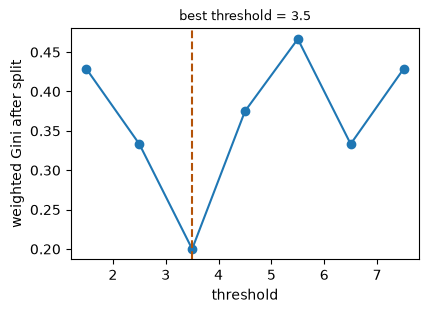

In [4]:
def split_search():
    x = np.array([1, 2, 3, 4, 5, 6, 7, 8])
    y = np.array([0, 0, 0, 1, 1, 0, 1, 1])
    thresholds = (x[:-1] + x[1:]) / 2

    def gini(part):
        p = part.mean() if len(part) else 0
        return 1 - p ** 2 - (1 - p) ** 2

    weighted = [(len(y[x <= t]) * gini(y[x <= t]) + len(y[x > t]) * gini(y[x > t])) / len(y) for t in thresholds]
    best = thresholds[int(np.argmin(weighted))]
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.plot(thresholds, weighted, "o-")
    ax.axvline(best, ls="--", color="#b45309")
    ax.set_xlabel("threshold")
    ax.set_ylabel("weighted Gini after split")
    ax.set_title(f"best threshold = {best}", fontsize=9)


split_search()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. gini() returns 0.0
2. gini() returns 0.489795918367347
3. gini() returns 0.0
4. gini() returns 0.4444444444444444
5. gini() returns 0.0
6. gini() returns 0.3199999999999999
7. gini() returns 0.375
8. gini() returns 0.375
9. gini() returns 0.48
10. gini() returns 0.4444444444444444
11. gini() returns 0.4444444444444443
12. gini() returns 0.0
13. gini() returns 0.489795918367347
14. gini() returns 0.0
15. split\_search() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q3](#q3), [Q9](#q9), [Q10](#q10), [Q11](#q11), [Q15](#q15), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 4: Growing, stopping and overfitting

*Level: Core*

The tree splits recursively until every leaf is pure — which memorises the training data (100% training accuracy, poor test accuracy). Stop it earlier (**pre-pruning**):



| Hyper-parameter | Effect |
| --- | --- |
| max\_depth | limit the number of questions in a row |
| min\_samples\_leaf | every leaf must keep at least this many rows |
| min\_samples\_split | a node needs this many rows to be split |
| max\_leaf\_nodes | grow best-first up to a leaf budget |
| ccp\_alpha | post-pruning: remove branches that don't pay for their complexity |



Trees are **unstable**: a small change in data can change the whole tree. That weakness is what ensembles (next topic) fix.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

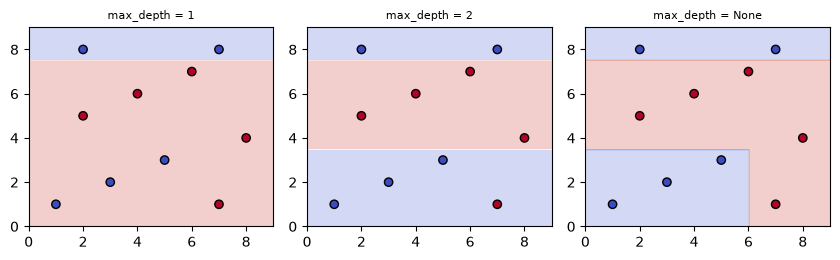

In [5]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
X3 = np.array([[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], dtype=float)
Y3 = np.array([0, 1, 0, 1, 0, 1, 1, 1, 0, 0])


def depth_regions():
    xx, yy = np.meshgrid(np.linspace(0, 9, 150), np.linspace(0, 9, 150))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.7))
    for ax, depth in zip(axes, [1, 2, None]):
        tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X3, Y3)
        ax.contourf(xx, yy, tree.predict(grid).reshape(xx.shape), alpha=0.25, cmap="coolwarm")
        ax.scatter(X3[:, 0], X3[:, 1], c=Y3, cmap="coolwarm", edgecolor="black")
        ax.set_title(f"max_depth = {depth}", fontsize=8)
    fig.tight_layout()


depth_regions()

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q12](#q12), [Q13](#q13), [Q14](#q14), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 5: Finding the best split, every candidate by hand

*Level: Core*

x = 1 to 8, labels y = 0, 0, 0, 1, 1, 0, 1, 1. The parent has 4 of each, so its Gini is 0.5.



Candidate thresholds are the midpoints between neighbouring values. For each: compute each side's Gini, then weight by size.



| Threshold | Left (no, yes) | Right (no, yes) | Gini L | Gini R | Weighted | Gain |
| --- | --- | --- | --- | --- | --- | --- |
| 1.5 | 1, 0 | 3, 4 | 0 | 0.490 | 0.429 | 0.071 |
| 2.5 | 2, 0 | 2, 4 | 0 | 0.444 | 0.333 | 0.167 |
| **3.5** | **3, 0** | **1, 4** | **0** | **0.320** | **0.200** | **0.300** |
| 4.5 | 3, 1 | 1, 3 | 0.375 | 0.375 | 0.375 | 0.125 |
| 5.5 | 3, 2 | 1, 2 | 0.480 | 0.444 | 0.467 | 0.033 |
| 6.5 | 4, 2 | 0, 2 | 0.444 | 0 | 0.333 | 0.167 |
| 7.5 | 4, 3 | 0, 1 | 0.490 | 0 | 0.429 | 0.071 |



Weighted example for 3.5: (3/8)(0) + (5/8)(0.32) = 0.2. The winner is **x ≤ 3.5**.



#### Now the same split with entropy



The parent is 1 bit. The right side is 0.722 bits, weighted (5/8) × 0.722 = 0.451. So **information gain = 1 − 0.451 = 0.549 bits**.



**Then what?** The left side is pure, so it becomes a leaf predicting 0. The right side (1 no, 4 yes) repeats the whole search. With many features, this table is built for every feature, and the best row overall wins.



**Greedy:** the tree takes the best split right now and never reconsiders, so it may miss a better tree overall.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [6]:
def split_table():
    x = np.arange(1, 9)
    y = np.array([0, 0, 0, 1, 1, 0, 1, 1])

    def gini_of(part):
        p = part.mean()
        return 1 - p ** 2 - (1 - p) ** 2

    table = {}
    for t in x[:-1] + 0.5:
        left, right = y[x <= t], y[x > t]
        weighted = (len(left) * gini_of(left) + len(right) * gini_of(right)) / len(y)
        table[float(t)] = round(0.5 - weighted, 3)
    best = max(table, key=table.get)


split_table()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. gini\_of() returns 0.0
2. gini\_of() returns 0.489795918367347
3. gini\_of() returns 0.0
4. gini\_of() returns 0.4444444444444444
5. gini\_of() returns 0.0
6. gini\_of() returns 0.3199999999999999
7. gini\_of() returns 0.375
8. gini\_of() returns 0.375
9. gini\_of() returns 0.48
10. gini\_of() returns 0.4444444444444444
11. gini\_of() returns 0.4444444444444443
12. gini\_of() returns 0.0
13. gini\_of() returns 0.489795918367347
14. gini\_of() returns 0.0
15. split\_table() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q3](#q3), [Q10](#q10), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 6: Regression trees by hand

*Level: Core*

The target is a number, so impurity becomes squared error around the mean. A leaf predicts its mean.



x = 1 to 6, y = 5, 6, 5.5, 12, 13, 12.5. The mean is 9, and the total squared error is **74.5**.



| Threshold | Left mean | Right mean | Total squared error after split |
| --- | --- | --- | --- |
| 1.5 | 5 | 9.8 | 55.3 |
| 2.5 | 5.5 | 10.75 | 37.75 |
| **3.5** | **5.5** | **12.5** | **1.0** |
| 4.5 | 7.125 | 12.75 | 32.31 |
| 5.5 | 8.3 | 12.5 | 59.8 |



The split at 3.5 removes almost all the error (from 74.5 down to 1.0). So: if x ≤ 3.5, predict 5.5; otherwise predict 12.5.



#### Consequences



- Predictions are a **staircase**: a tree can only output values it stored.
- Asked about x = 100, it still says 12.5. **Trees can't extrapolate** a trend, so they struggle with forecasting growing values.
- Outliers: squared error is affected by them; try `criterion="absolute_error"`.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

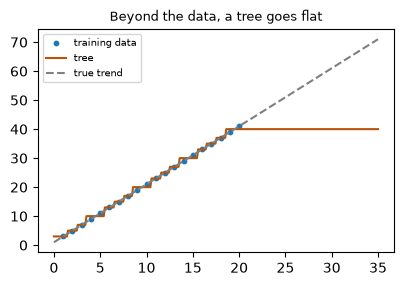

In [7]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree


def no_extrapolation():
    x = np.arange(1, 21, dtype=float).reshape(-1, 1)
    y = 2 * x.ravel() + 1
    grid = np.linspace(0, 35, 300).reshape(-1, 1)
    tree = DecisionTreeRegressor(max_depth=4, random_state=0).fit(x, y)
    fig, ax = plt.subplots(figsize=(4.6, 2.9))
    ax.scatter(x, y, s=10, label="training data")
    ax.plot(grid, tree.predict(grid), color="#b45309", label="tree")
    ax.plot(grid, 2 * grid + 1, "--", color="gray", label="true trend")
    ax.legend(fontsize=7)
    ax.set_title("Beyond the data, a tree goes flat", fontsize=9)


no_extrapolation()

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 7: Regression trees and feature importance

*Level: Advanced*

For numbers, the impurity is the variance (MSE) and each leaf predicts the mean — so the prediction curve is a **staircase**. Trees can't extrapolate beyond the range they saw.



**Feature importance** (mean decrease in impurity) adds up, for each feature, how much impurity its splits removed, weighted by the share of rows they affected, then normalises to 1. Fast, but biased towards features with many distinct values — **permutation importance** on validation data is more trustworthy.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

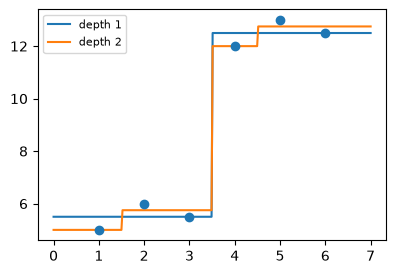

In [8]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree


def staircase():
    x = np.array([1, 2, 3, 4, 5, 6], dtype=float).reshape(-1, 1)
    y = np.array([5.0, 6.0, 5.5, 12.0, 13.0, 12.5])
    grid = np.linspace(0, 7, 300).reshape(-1, 1)
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.scatter(x, y, zorder=3)
    for depth in [1, 2]:
        ax.plot(grid, DecisionTreeRegressor(max_depth=depth, random_state=0).fit(x, y).predict(grid), label=f"depth {depth}")
    ax.legend(fontsize=8)


staircase()

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q17](#q17), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 8: Pruning: cost-complexity by hand

*Level: Advanced*

Limits like `max_depth` stop growth early, and they may stop before a useful split. **Post-pruning** grows the full tree first, then removes branches that don't earn their place.



#### The rule



**cost = impurity of the leaves + α × number of leaves**



#### Worked example



| Option | Total impurity | Leaves | Cost with α = 0.01 | Cost with α = 0.05 |
| --- | --- | --- | --- | --- |
| Keep the branch | 0.10 | 4 | 0.14 | **0.30** |
| Prune the branch | 0.15 | 2 | 0.17 | **0.25** |



At α = 0.01 keeping wins (0.14 is lower). At α = 0.05 pruning wins (0.25 is lower). A branch survives only if its drop in impurity pays for its extra leaves.



Larger α means a smaller tree. Choose α with cross-validation: `cost_complexity_pruning_path` lists the useful values. The demo shows it: training accuracy falls as the tree shrinks, while test accuracy first improves, because the removed branches were mostly fitting noise. Prune too far and test accuracy falls as well.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

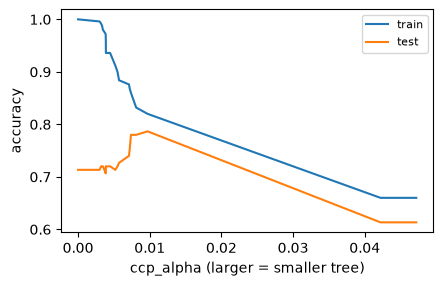

In [9]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree


def pruning_curve():
    rng = np.random.default_rng(0)
    X = rng.uniform(0, 10, (400, 2))
    y = ((X[:, 0] - 5) ** 2 + (X[:, 1] - 5) ** 2 < 9).astype(int)
    flip = rng.uniform(size=400) < 0.15
    y = np.where(flip, 1 - y, y)
    X_train, X_test, y_train, y_test = X[:250], X[250:], y[:250], y[250:]
    path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(X_train, y_train)
    alphas = path.ccp_alphas
    trees = [DecisionTreeClassifier(ccp_alpha=a, random_state=0).fit(X_train, y_train) for a in alphas]
    fig, ax = plt.subplots(figsize=(4.8, 2.9))
    ax.plot(alphas, [t.score(X_train, y_train) for t in trees], label="train")
    ax.plot(alphas, [t.score(X_test, y_test) for t in trees], label="test")
    ax.set_xlabel("ccp_alpha (larger = smaller tree)")
    ax.set_ylabel("accuracy")
    ax.legend(fontsize=8)


pruning_curve()

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q13](#q13), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 9: Importance, instability and when to use trees

*Level: Advanced*

#### Two kinds of feature importance



|   | Impurity-based | Permutation |
| --- | --- | --- |
| How | adds up each feature's impurity decreases | shuffles one column, measures how much the score drops |
| Speed | instant | needs repeated scoring |
| Weakness | favours features with many distinct values; reflects training data | splits credit between correlated features |



The demo adds a random ID column. Impurity importance gives this useless column real credit. Permutation importance on test data shows it's worth nothing.



#### Instability



A small change in the data can change the first split, and then every split below it. That's high variance, and exactly why forests average many trees.



#### Should you use a single tree?



- **Yes** when a human must follow the rules: credit policies, triage, explaining patterns.
- **Usually no** for best accuracy: use a forest or boosting.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

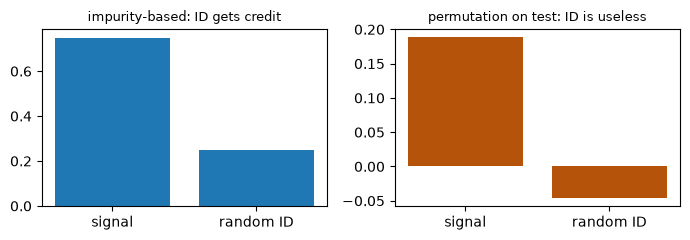

In [10]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree


def fake_feature():
    from sklearn.inspection import permutation_importance
    rng = np.random.default_rng(0)
    signal = rng.normal(size=400)
    row_id = rng.permutation(400).astype(float)
    y = (signal + rng.normal(0, 0.7, 400) > 0).astype(int)
    X = np.column_stack([signal, row_id])
    tree = DecisionTreeClassifier(random_state=0).fit(X[:280], y[:280])
    perm = permutation_importance(tree, X[280:], y[280:], n_repeats=10, random_state=0)
    fig, axes = plt.subplots(1, 2, figsize=(7, 2.5))
    axes[0].bar(["signal", "random ID"], tree.feature_importances_)
    axes[0].set_title("impurity-based: ID gets credit", fontsize=9)
    axes[1].bar(["signal", "random ID"], perm.importances_mean, color="#b45309")
    axes[1].set_title("permutation on test: ID is useless", fontsize=9)
    fig.tight_layout()


fake_feature()

**✏️ Your turn:** you now have what you need for [Q20](#q20), [Q6](#q6). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [11]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

import math


<a id="q1"></a>
### Q1. Gini Impurity of a Node

🟢 Warm-up · *How mixed are the labels?*

Return 1 − Σ (share of each class)², rounded to 4 decimals.

**Examples**

- `y = [0, 0, 0, 1, 1, 0, 1, 1]` → `0.5`
- `y = [1, 1, 1]` → `0.0`
- `y = ['a', 'b', 'c', 'c']` → `0.625`

In [ ]:
def gini(y):
    """
    Return 1 − Σ (share of each class)², rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gini, [
    (([0, 0, 0, 1, 1, 0, 1, 1],), 0.5),
    (([1, 1, 1],), 0.0),
    ((['a', 'b', 'c', 'c'],), 0.625),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count each class, apply the formula.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Fit a tree; the root node's `tree_.impurity[0]` is the Gini of all the labels.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count each class, apply the formula.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n


def gini(y):
    return round(impurity(y, "gini"), 4)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Fit a tree; the root node's `tree_.impurity[0]` is the Gini of all the labels.

```python
def gini(y):
    tree = DecisionTreeClassifier(max_depth=1, random_state=0).fit(np.zeros((len(y), 1)), y)
    return round(tree.tree_.impurity[0], 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count each class, apply the formula. That costs O(n) time and O(k) space."

"I can do better: Fit a tree; the root node's `tree_.impurity[0]` is the Gini of all the labels. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/gini-impurity-of-a-node)

<a id="q2"></a>
### Q2. Entropy of a Node

🟢 Warm-up · *Impurity in bits*

Return −Σ p log₂ p over the classes, rounded to 4 decimals.

**Examples**

- `y = [0, 0, 0, 1, 1, 0, 1, 1]` → `1.0`
- `y = ['a', 'b', 'c', 'c']` → `1.5`

In [ ]:
def entropy(y):
    """
    Return −Σ p log₂ p over the classes, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(entropy, [
    (([0, 0, 0, 1, 1, 0, 1, 1],), 1.0),
    ((['a', 'b', 'c', 'c'],), 1.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count each class, apply the formula.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Root impurity of a tree with `criterion='entropy'`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count each class, apply the formula.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n


def entropy(y):
    return round(impurity(y, "entropy"), 4)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Root impurity of a tree with `criterion='entropy'`.

```python
def entropy(y):
    tree = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=0).fit(np.zeros((len(y), 1)), y)
    return round(tree.tree_.impurity[0], 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count each class, apply the formula. That costs O(n) time and O(k) space."

"I can do better: Root impurity of a tree with `criterion='entropy'`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/entropy-of-a-node)

<a id="q3"></a>
### Q3. Weighted Gini of a Given Split

🟢 Warm-up · *Scoring one candidate question*

Split one feature at threshold t (x ≤ t goes left). Return the size-weighted Gini of the two sides, rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1], t = 3.5` → `0.2`
- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1], t = 5.5` → `0.4667`

In [ ]:
def split_gini(X, y, t):
    """
    Split one feature at threshold t (x ≤ t goes left). Return the size-weighted
    Gini of the two sides, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(split_gini, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1], 3.5), 0.2),
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1], 5.5), 0.4667),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Divide the labels, compute each side's Gini, weight by size.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised with NumPy masks and class counts (`np.unique`).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Divide the labels, compute each side's Gini, weight by size.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n


def split_gini(X, y, t):
    left = [label for row, label in zip(X, y) if row[0] <= t]
    right = [label for row, label in zip(X, y) if row[0] > t]
    return round((len(left) * impurity(left) + len(right) * impurity(right)) / len(y), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Vectorised with NumPy masks and class counts (`np.unique`).

```python
def split_gini(X, y, t):
    x, labels = np.array(X)[:, 0], np.array(y)

    def g(part):
        _, counts = np.unique(part, return_counts=True)
        return 1 - ((counts / counts.sum()) ** 2).sum()

    mask = x <= t
    return round((mask.sum() * g(labels[mask]) + (~mask).sum() * g(labels[~mask])) / len(labels), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Divide the labels, compute each side's Gini, weight by size. That costs O(n) time and O(n) space."

"I can do better: Vectorised with NumPy masks and class counts (`np.unique`). That's O(n) time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1], t = 3.5`

1. g() returns 0.0
2. g() returns 0.31999999999999984
3. split\_gini() returns 0.2

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/weighted-gini-of-a-given-split)

<a id="q4"></a>
### Q4. Predict With a Stump

🟢 Warm-up · *One question, two answers*

Train a depth-1 tree on (X, y) and predict the class of each query row.

**Examples**

- `X = [[2, 3], [1, 1], [4, 5], [6, 2], [7, 6], [3, 7], [8, 4], [5, 1]], y = [0, 0, 1, 0, 1, 1, 1, 0], queries = [[1, 9], [7, 1], [5, 5]]` → `[1, 0, 1]`

In [ ]:
def stump_predict(X, y, queries):
    """
    Train a depth-1 tree on (X, y) and predict the class of each query row.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stump_predict, [
    (([[2, 3], [1, 1], [4, 5], [6, 2], [7, 6], [3, 7], [8, 4], [5, 1]], [0, 0, 1, 0, 1, 1, 1, 0], [[1, 9], [7, 1], [5, 5]]), [1, 0, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find the root split; each side predicts its majority class.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`DecisionTreeClassifier(max_depth=1).predict`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Find the root split; each side predicts its majority class.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best

def grow(X, y, depth=0, max_depth=None, criterion="gini"):
    """A node is either {'leaf': labels} or {'f', 't', 'left', 'right', 'n', 'imp'}."""
    gain, f, t = best_split(X, y, criterion)
    if f is None or (max_depth is not None and depth >= max_depth):
        return {"leaf": y}
    li = [i for i, row in enumerate(X) if row[f] <= t]
    ri = [i for i, row in enumerate(X) if row[f] > t]
    return {"f": f, "t": t, "n": len(y), "imp": impurity(y, criterion),
            "left": grow([X[i] for i in li], [y[i] for i in li], depth + 1, max_depth, criterion),
            "right": grow([X[i] for i in ri], [y[i] for i in ri], depth + 1, max_depth, criterion)}

def leaf_for(node, row):
    while "leaf" not in node:
        node = node["left"] if row[node["f"]] <= node["t"] else node["right"]
    return node["leaf"]

def majority(labels):
    return max(sorted(set(labels)), key=labels.count)


def stump_predict(X, y, queries):
    tree = grow(X, y, max_depth=1)
    return [majority(leaf_for(tree, q)) for q in queries]
```

**Cost:** O(d·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `DecisionTreeClassifier(max_depth=1).predict`.

```python
def stump_predict(X, y, queries):
    return DecisionTreeClassifier(max_depth=1, random_state=0).fit(X, y).predict(queries)
```

**Cost:** O(d·n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find the root split; each side predicts its majority class. That costs O(d·n²) time and O(n) space."

"I can do better: `DecisionTreeClassifier(max_depth=1).predict`. That's O(d·n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/predict-with-a-stump)

<a id="q5"></a>
### Q5. Leaf Probabilities

🟢 Warm-up · *Class shares inside a leaf*

Train a depth-1 tree and return P(class) for the query (sorted classes), rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1], q = [7.5]` → `[0.2, 0.8]`
- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1], q = [2]` → `[1.0, 0.0]`

In [ ]:
def leaf_proba(X, y, q):
    """
    Train a depth-1 tree and return P(class) for the query (sorted classes),
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(leaf_proba, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1], [7.5]), [0.2, 0.8]),
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1], [2]), [1.0, 0.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find the query's leaf; class shares of the training labels there.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`predict_proba`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Find the query's leaf; class shares of the training labels there.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best

def grow(X, y, depth=0, max_depth=None, criterion="gini"):
    """A node is either {'leaf': labels} or {'f', 't', 'left', 'right', 'n', 'imp'}."""
    gain, f, t = best_split(X, y, criterion)
    if f is None or (max_depth is not None and depth >= max_depth):
        return {"leaf": y}
    li = [i for i, row in enumerate(X) if row[f] <= t]
    ri = [i for i, row in enumerate(X) if row[f] > t]
    return {"f": f, "t": t, "n": len(y), "imp": impurity(y, criterion),
            "left": grow([X[i] for i in li], [y[i] for i in li], depth + 1, max_depth, criterion),
            "right": grow([X[i] for i in ri], [y[i] for i in ri], depth + 1, max_depth, criterion)}

def leaf_for(node, row):
    while "leaf" not in node:
        node = node["left"] if row[node["f"]] <= node["t"] else node["right"]
    return node["leaf"]


def leaf_proba(X, y, q):
    labels = leaf_for(grow(X, y, max_depth=1), q)
    return [round(labels.count(c) / len(labels), 4) for c in sorted(set(y))]
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `predict_proba`.

```python
def leaf_proba(X, y, q):
    return DecisionTreeClassifier(max_depth=1, random_state=0).fit(X, y).predict_proba([q])[0].round(4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find the query's leaf; class shares of the training labels there. That costs O(n²) time and O(n) space."

"I can do better: `predict_proba`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/leaf-probabilities)

<a id="q6"></a>
### Q6. Which Leaf Does Each Row Reach?

🟢 Warm-up · *apply()*

For a depth-1 tree, return the node id each query lands in (left leaf = 1, right leaf = 2).

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1], queries = [[1], [5], [8]]` → `[1, 2, 2]`

In [ ]:
def leaf_ids(X, y, queries):
    """
    For a depth-1 tree, return the node id each query lands in (left leaf = 1,
    right leaf = 2).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(leaf_ids, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1], [[1], [5], [8]]), [1, 2, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compare with the root threshold.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`tree.apply(queries)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Compare with the root threshold.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best


def leaf_ids(X, y, queries):
    gain, f, t = best_split(X, y)
    return [1 if q[f] <= t else 2 for q in queries]
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `tree.apply(queries)`.

```python
def leaf_ids(X, y, queries):
    return DecisionTreeClassifier(max_depth=1, random_state=0).fit(X, y).apply(queries)
```

**Cost:** O(n log n) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compare with the root threshold. That costs O(n²) time and O(1) space."

"I can do better: `tree.apply(queries)`. That's O(n log n) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/which-leaf-does-each-row-reach)

<a id="q7"></a>
### Q7. Samples in Each Leaf

🟢 Warm-up · *How the data is divided*

For a depth-1 tree, return (samples in the left leaf, samples in the right leaf).

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1]` → `(3, 5)`
- `X = [[2, 3], [1, 1], [4, 5], [6, 2], [7, 6], [3, 7], [8, 4], [5, 1]], y = [0, 0, 1, 0, 1, 1, 1, 0]` → `(4, 4)`

In [ ]:
def leaf_sizes(X, y):
    """
    For a depth-1 tree, return (samples in the left leaf, samples in the right
    leaf).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(leaf_sizes, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1]), (3, 5)),
    (([[2, 3], [1, 1], [4, 5], [6, 2], [7, 6], [3, 7], [8, 4], [5, 1]], [0, 0, 1, 0, 1, 1, 1, 0]), (4, 4)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count rows on each side of the root threshold.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`tree_.n_node_samples[1:]`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count rows on each side of the root threshold.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best


def leaf_sizes(X, y):
    gain, f, t = best_split(X, y)
    left = sum(1 for row in X if row[f] <= t)
    return (left, len(X) - left)
```

**Cost:** O(d·n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `tree_.n_node_samples[1:]`.

```python
def leaf_sizes(X, y):
    t = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X, y).tree_
    return (int(t.n_node_samples[1]), int(t.n_node_samples[2]))
```

**Cost:** O(d·n log n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count rows on each side of the root threshold. That costs O(d·n²) time and O(1) space."

"I can do better: `tree_.n_node_samples[1:]`. That's O(d·n log n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/samples-in-each-leaf)

<a id="q8"></a>
### Q8. Majority Class at the Root

🟢 Warm-up · *A tree with no questions*

A tree of depth 0 would predict the most common class (smallest on ties). Return it, and the training accuracy of that guess (rounded to 4 decimals).

**Examples**

- `y = [0, 0, 0, 1, 1, 0, 1, 1]` → `(0, 0.5)`
- `y = ['b', 'a', 'b', 'c']` → `('b', 0.5)`

In [ ]:
def root_majority(y):
    """
    A tree of depth 0 would predict the most common class (smallest on ties).
    Return it, and the training accuracy of that guess (rounded to 4 decimals).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(root_majority, [
    (([0, 0, 0, 1, 1, 0, 1, 1],), (0, 0.5)),
    ((['b', 'a', 'b', 'c'],), ('b', 0.5)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count classes; the winner's share is the accuracy.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The class with the largest share in the root's `tree_.value`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count classes; the winner's share is the accuracy.

```python
def majority(labels):
    return max(sorted(set(labels)), key=labels.count)


def root_majority(y):
    winner = majority(y)
    return (winner, round(y.count(winner) / len(y), 4))
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** The class with the largest share in the root's `tree_.value`.

```python
def root_majority(y):
    tree = DecisionTreeClassifier(max_depth=1, random_state=0).fit(np.zeros((len(y), 1)), y)
    shares = tree.tree_.value[0][0] / tree.tree_.value[0][0].sum()
    i = int(np.argmax(shares))
    return (tree.classes_[i].item(), round(shares[i], 4))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count classes; the winner's share is the accuracy. That costs O(n) time and O(k) space."

"I can do better: The class with the largest share in the root's `tree_.value`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/majority-class-at-the-root)

<a id="q9"></a>
### Q9. Best Split Threshold

🟡 Interview standard · *The root question*

One feature. Return the threshold (midpoint between neighbouring values) that gives the largest drop in Gini.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1]` → `3.5`
- `X = [[1], [3], [4], [7], [9]], y = ['a', 'a', 'b', 'b', 'b']` → `3.5`

In [ ]:
def best_threshold(X, y):
    """
    One feature. Return the threshold (midpoint between neighbouring values)
    that gives the largest drop in Gini.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(best_threshold, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1]), 3.5),
    (([[1], [3], [4], [7], [9]], ['a', 'a', 'b', 'b', 'b']), 3.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Try every midpoint; compute the size-weighted Gini of both sides; keep the best.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A depth-1 tree (a **stump**): `tree_.threshold[0]`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Try every midpoint; compute the size-weighted Gini of both sides; keep the best.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best


def best_threshold(X, y):
    return best_split(X, y)[2]
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A depth-1 tree (a **stump**): `tree_.threshold[0]`.

```python
def best_threshold(X, y):
    return DecisionTreeClassifier(max_depth=1, random_state=0).fit(X, y).tree_.threshold[0]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Try every midpoint; compute the size-weighted Gini of both sides; keep the best. That costs O(n²) time and O(n) space."

"I can do better: A depth-1 tree (a **stump**): `tree_.threshold[0]`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/best-split-threshold)

<a id="q10"></a>
### Q10. Impurity Decrease of the Best Split

🟡 Interview standard · *Information gain (Gini)*

Return parent Gini − weighted child Gini for the best split, rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1]` → `0.3`
- `X = [[2, 3], [1, 1], [4, 5], [6, 2], [7, 6], [3, 7], [8, 4], [5, 1]], y = [0, 0, 1, 0, 1, 1, 1, 0]` → `0.5`

In [ ]:
def split_gain(X, y):
    """
    Return parent Gini − weighted child Gini for the best split, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(split_gain, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1]), 0.3),
    (([[2, 3], [1, 1], [4, 5], [6, 2], [7, 6], [3, 7], [8, 4], [5, 1]], [0, 0, 1, 0, 1, 1, 1, 0]), 0.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

The best\_split search returns the gain directly.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

From a stump: root impurity minus the size-weighted impurity of its two children.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** The best\_split search returns the gain directly.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best


def split_gain(X, y):
    return round(best_split(X, y)[0], 4)
```

**Cost:** O(d·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** From a stump: root impurity minus the size-weighted impurity of its two children.

```python
def split_gain(X, y):
    t = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X, y).tree_
    n = t.weighted_n_node_samples
    return round(t.impurity[0] - (n[1] * t.impurity[1] + n[2] * t.impurity[2]) / n[0], 4)
```

**Cost:** O(d·n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: The best\_split search returns the gain directly. That costs O(d·n²) time and O(n) space."

"I can do better: From a stump: root impurity minus the size-weighted impurity of its two children. That's O(d·n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/impurity-decrease-of-the-best-split)

<a id="q11"></a>
### Q11. Which Feature Splits Best?

🟡 Interview standard · *Choosing the question*

Two features. Return (feature index, threshold) of the root split.

**Examples**

- `X = [[2, 3], [1, 1], [4, 5], [6, 2], [7, 6], [3, 7], [8, 4], [5, 1]], y = [0, 0, 1, 0, 1, 1, 1, 0]` → `(1, 3.5)`

In [ ]:
def root_question(X, y):
    """
    Two features. Return (feature index, threshold) of the root split.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(root_question, [
    (([[2, 3], [1, 1], [4, 5], [6, 2], [7, 6], [3, 7], [8, 4], [5, 1]], [0, 0, 1, 0, 1, 1, 1, 0]), (1, 3.5)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Search both features and all midpoints.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Stump: `tree_.feature[0]` and `tree_.threshold[0]`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Search both features and all midpoints.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best


def root_question(X, y):
    gain, f, t = best_split(X, y)
    return (f, t)
```

**Cost:** O(d·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Stump: `tree_.feature[0]` and `tree_.threshold[0]`.

```python
def root_question(X, y):
    t = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X, y).tree_
    return (int(t.feature[0]), float(t.threshold[0]))
```

**Cost:** O(d·n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Search both features and all midpoints. That costs O(d·n²) time and O(n) space."

"I can do better: Stump: `tree_.feature[0]` and `tree_.threshold[0]`. That's O(d·n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/which-feature-splits-best)

<a id="q12"></a>
### Q12. How Deep Does It Grow?

🟡 Interview standard · *Unlimited depth*

Grow a tree with no depth limit until every leaf is pure. Return (depth, number of leaves).

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1]` → `(3, 4)`
- `X = [[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], y = [0, 1, 0, 1, 0, 1, 1, 1, 0, 0]` → `(3, 4)`

In [ ]:
def size_of_tree(X, y):
    """
    Grow a tree with no depth limit until every leaf is pure. Return (depth,
    number of leaves).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(size_of_tree, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1]), (3, 4)),
    (([[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], [0, 1, 0, 1, 0, 1, 1, 1, 0, 0]), (3, 4)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Recursive builder, then count levels and leaves.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`get_depth()` and `get_n_leaves()`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Recursive builder, then count levels and leaves.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best

def grow(X, y, depth=0, max_depth=None, criterion="gini"):
    """A node is either {'leaf': labels} or {'f', 't', 'left', 'right', 'n', 'imp'}."""
    gain, f, t = best_split(X, y, criterion)
    if f is None or (max_depth is not None and depth >= max_depth):
        return {"leaf": y}
    li = [i for i, row in enumerate(X) if row[f] <= t]
    ri = [i for i, row in enumerate(X) if row[f] > t]
    return {"f": f, "t": t, "n": len(y), "imp": impurity(y, criterion),
            "left": grow([X[i] for i in li], [y[i] for i in li], depth + 1, max_depth, criterion),
            "right": grow([X[i] for i in ri], [y[i] for i in ri], depth + 1, max_depth, criterion)}


def size_of_tree(X, y):
    def depth(node):
        return 0 if "leaf" in node else 1 + max(depth(node["left"]), depth(node["right"]))

    def leaves(node):
        return 1 if "leaf" in node else leaves(node["left"]) + leaves(node["right"])

    tree = grow(X, y)
    return (depth(tree), leaves(tree))
```

**Cost:** O(d·n² · nodes) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `get_depth()` and `get_n_leaves()`.

```python
def size_of_tree(X, y):
    tree = DecisionTreeClassifier(random_state=0).fit(X, y)
    return (tree.get_depth(), tree.get_n_leaves())
```

**Cost:** O(d·n log n · depth) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Recursive builder, then count levels and leaves. That costs O(d·n² · nodes) time and O(n) space."

"I can do better: `get_depth()` and `get_n_leaves()`. That's O(d·n log n · depth) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/how-deep-does-it-grow)

<a id="q13"></a>
### Q13. Training Accuracy by Depth

🟡 Interview standard · *Deeper = memorises more*

Return the training accuracy of trees with max\_depth = 1, 2, 3, rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], y = [0, 1, 0, 1, 0, 1, 1, 1, 0, 0]` → `[0.7, 0.9, 1.0]`

In [ ]:
def accuracy_by_depth(X, y):
    """
    Return the training accuracy of trees with max_depth = 1, 2, 3, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(accuracy_by_depth, [
    (([[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], [0, 1, 0, 1, 0, 1, 1, 1, 0, 0]), [0.7, 0.9, 1.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build each tree from scratch and score it on its own training data.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Fit three `DecisionTreeClassifier`s and call `score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Build each tree from scratch and score it on its own training data.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best

def grow(X, y, depth=0, max_depth=None, criterion="gini"):
    """A node is either {'leaf': labels} or {'f', 't', 'left', 'right', 'n', 'imp'}."""
    gain, f, t = best_split(X, y, criterion)
    if f is None or (max_depth is not None and depth >= max_depth):
        return {"leaf": y}
    li = [i for i, row in enumerate(X) if row[f] <= t]
    ri = [i for i, row in enumerate(X) if row[f] > t]
    return {"f": f, "t": t, "n": len(y), "imp": impurity(y, criterion),
            "left": grow([X[i] for i in li], [y[i] for i in li], depth + 1, max_depth, criterion),
            "right": grow([X[i] for i in ri], [y[i] for i in ri], depth + 1, max_depth, criterion)}

def leaf_for(node, row):
    while "leaf" not in node:
        node = node["left"] if row[node["f"]] <= node["t"] else node["right"]
    return node["leaf"]

def majority(labels):
    return max(sorted(set(labels)), key=labels.count)


def accuracy_by_depth(X, y):
    out = []
    for d in (1, 2, 3):
        tree = grow(X, y, max_depth=d)
        correct = sum(majority(leaf_for(tree, row)) == label for row, label in zip(X, y))
        out.append(round(correct / len(y), 4))
    return out
```

**Cost:** O(depth·d·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Fit three `DecisionTreeClassifier`s and call `score`.

```python
def accuracy_by_depth(X, y):
    return [round(DecisionTreeClassifier(max_depth=d, random_state=0).fit(X, y).score(X, y), 4) for d in (1, 2, 3)]
```

**Cost:** O(depth·d·n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build each tree from scratch and score it on its own training data. That costs O(depth·d·n²) time and O(n) space."

"I can do better: Fit three `DecisionTreeClassifier`s and call `score`. That's O(depth·d·n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/training-accuracy-by-depth)

<a id="q14"></a>
### Q14. Minimum Samples per Leaf

🟡 Interview standard · *A brake on overfitting*

Find the best stump threshold when each side must keep at least min\_leaf samples.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1], min_leaf = 1` → `3.5`
- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1], min_leaf = 4` → `4.5`

In [ ]:
def constrained_threshold(X, y, min_leaf):
    """
    Find the best stump threshold when each side must keep at least min_leaf
    samples.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(constrained_threshold, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1], 1), 3.5),
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1], 4), 4.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Same search, skipping splits that leave a side too small.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`DecisionTreeClassifier(max_depth=1, min_samples_leaf=…)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Same search, skipping splits that leave a side too small.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best


def constrained_threshold(X, y, min_leaf):
    return best_split(X, y, min_leaf=min_leaf)[2]
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `DecisionTreeClassifier(max_depth=1, min_samples_leaf=…)`.

```python
def constrained_threshold(X, y, min_leaf):
    tree = DecisionTreeClassifier(max_depth=1, min_samples_leaf=min_leaf, random_state=0).fit(X, y)
    return tree.tree_.threshold[0]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Same search, skipping splits that leave a side too small. That costs O(n²) time and O(n) space."

"I can do better: `DecisionTreeClassifier(max_depth=1, min_samples_leaf=…)`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/minimum-samples-per-leaf)

<a id="q15"></a>
### Q15. Gini vs Entropy

🟡 Interview standard · *Do they pick the same question?*

Return (best threshold by Gini, best threshold by entropy) for a single feature.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6], [7], [8]], y = [0, 0, 0, 1, 1, 0, 1, 1]` → `(3.5, 3.5)`
- `X = [[1], [2], [3], [4], [5], [6]], y = ['a', 'a', 'b', 'c', 'c', 'c']` → `(3.5, 3.5)`

In [ ]:
def gini_vs_entropy(X, y):
    """
    Return (best threshold by Gini, best threshold by entropy) for a single
    feature.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gini_vs_entropy, [
    (([[1], [2], [3], [4], [5], [6], [7], [8]], [0, 0, 0, 1, 1, 0, 1, 1]), (3.5, 3.5)),
    (([[1], [2], [3], [4], [5], [6]], ['a', 'a', 'b', 'c', 'c', 'c']), (3.5, 3.5)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Run the split search with each criterion.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Two stumps with different `criterion`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Run the split search with each criterion.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best


def gini_vs_entropy(X, y):
    return (best_split(X, y, "gini")[2], best_split(X, y, "entropy")[2])
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Two stumps with different `criterion`.

```python
def gini_vs_entropy(X, y):
    g = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X, y).tree_.threshold[0]
    e = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=0).fit(X, y).tree_.threshold[0]
    return (float(g), float(e))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Run the split search with each criterion. That costs O(n²) time and O(n) space."

"I can do better: Two stumps with different `criterion`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/gini-vs-entropy)

<a id="q16"></a>
### Q16. Regression Stump

🟡 Interview standard · *Split to reduce squared error*

One feature, numeric target. Return (threshold, left-leaf mean, right-leaf mean) of a depth-1 regression tree, rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6]], y = [5.0, 6.0, 5.5, 12.0, 13.0, 12.5]` → `(3.5, 5.5, 12.5)`

In [ ]:
def regression_stump(X, y):
    """
    One feature, numeric target. Return (threshold, left-leaf mean, right-leaf
    mean) of a depth-1 regression tree, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(regression_stump, [
    (([[1], [2], [3], [4], [5], [6]], [5.0, 6.0, 5.5, 12.0, 13.0, 12.5]), (3.5, 5.5, 12.5)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Same split search with variance (MSE) as the impurity; leaves predict their mean.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`DecisionTreeRegressor(max_depth=1)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Same split search with variance (MSE) as the impurity; leaves predict their mean.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best


def regression_stump(X, y):
    gain, f, t = best_split(X, y, "mse")
    left = [v for row, v in zip(X, y) if row[f] <= t]
    right = [v for row, v in zip(X, y) if row[f] > t]
    return (t, round(sum(left) / len(left), 4), round(sum(right) / len(right), 4))
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `DecisionTreeRegressor(max_depth=1)`.

```python
def regression_stump(X, y):
    tree = DecisionTreeRegressor(max_depth=1, random_state=0).fit(X, y)
    t = tree.tree_
    return (float(t.threshold[0]), round(t.value[1][0][0], 4), round(t.value[2][0][0], 4))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Same split search with variance (MSE) as the impurity; leaves predict their mean. That costs O(n²) time and O(n) space."

"I can do better: `DecisionTreeRegressor(max_depth=1)`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/regression-stump)

<a id="q17"></a>
### Q17. Regression Tree Predictions

🟡 Interview standard · *Step-shaped curves*

Train a regression tree with max\_depth = 2 and predict each query, rounded to 4 decimals.

**Examples**

- `X = [[1], [2], [3], [4], [5], [6]], y = [5.0, 6.0, 5.5, 12.0, 13.0, 12.5], queries = [[0], [2.5], [3.7], [6.5]]` → `[5.0, 5.75, 12.0, 12.75]`

In [ ]:
def regression_tree(X, y, queries):
    """
    Train a regression tree with max_depth = 2 and predict each query, rounded
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(regression_tree, [
    (([[1], [2], [3], [4], [5], [6]], [5.0, 6.0, 5.5, 12.0, 13.0, 12.5], [[0], [2.5], [3.7], [6.5]]), [5.0, 5.75, 12.0, 12.75]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Recursive builder with MSE impurity; each leaf predicts the mean of its targets.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`DecisionTreeRegressor(max_depth=2).predict`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Recursive builder with MSE impurity; each leaf predicts the mean of its targets.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best

def grow(X, y, depth=0, max_depth=None, criterion="gini"):
    """A node is either {'leaf': labels} or {'f', 't', 'left', 'right', 'n', 'imp'}."""
    gain, f, t = best_split(X, y, criterion)
    if f is None or (max_depth is not None and depth >= max_depth):
        return {"leaf": y}
    li = [i for i, row in enumerate(X) if row[f] <= t]
    ri = [i for i, row in enumerate(X) if row[f] > t]
    return {"f": f, "t": t, "n": len(y), "imp": impurity(y, criterion),
            "left": grow([X[i] for i in li], [y[i] for i in li], depth + 1, max_depth, criterion),
            "right": grow([X[i] for i in ri], [y[i] for i in ri], depth + 1, max_depth, criterion)}

def leaf_for(node, row):
    while "leaf" not in node:
        node = node["left"] if row[node["f"]] <= node["t"] else node["right"]
    return node["leaf"]


def regression_tree(X, y, queries):
    tree = grow(X, y, max_depth=2, criterion="mse")
    out = []
    for q in queries:
        values = leaf_for(tree, q)
        out.append(round(sum(values) / len(values), 4))
    return out
```

**Cost:** O(n² · nodes) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `DecisionTreeRegressor(max_depth=2).predict`.

```python
def regression_tree(X, y, queries):
    return DecisionTreeRegressor(max_depth=2, random_state=0).fit(X, y).predict(queries).round(4)
```

**Cost:** O(n log n · depth) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Recursive builder with MSE impurity; each leaf predicts the mean of its targets. That costs O(n² · nodes) time and O(n) space."

"I can do better: `DecisionTreeRegressor(max_depth=2).predict`. That's O(n log n · depth) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/regression-tree-predictions)

<a id="q18"></a>
### Q18. A Depth-2 Tree

🔴 Stretch · *Growing recursively*

Train a tree with max\_depth = 2 and predict the class of each query row.

**Examples**

- `X = [[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], y = [0, 1, 0, 1, 0, 1, 1, 1, 0, 0], queries = [[1, 9], [7, 1], [5, 5], [2, 2], [8, 8]]` → `[0, 0, 1, 0, 0]`

In [ ]:
def depth2_predict(X, y, queries):
    """
    Train a tree with max_depth = 2 and predict the class of each query row.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(depth2_predict, [
    (([[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], [0, 1, 0, 1, 0, 1, 1, 1, 0, 0], [[1, 9], [7, 1], [5, 5], [2, 2], [8, 8]]), [0, 0, 1, 0, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Recursive builder: best split, then the same on each side, stopping at depth 2 or pure nodes.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`DecisionTreeClassifier(max_depth=2)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Recursive builder: best split, then the same on each side, stopping at depth 2 or pure nodes.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best

def grow(X, y, depth=0, max_depth=None, criterion="gini"):
    """A node is either {'leaf': labels} or {'f', 't', 'left', 'right', 'n', 'imp'}."""
    gain, f, t = best_split(X, y, criterion)
    if f is None or (max_depth is not None and depth >= max_depth):
        return {"leaf": y}
    li = [i for i, row in enumerate(X) if row[f] <= t]
    ri = [i for i, row in enumerate(X) if row[f] > t]
    return {"f": f, "t": t, "n": len(y), "imp": impurity(y, criterion),
            "left": grow([X[i] for i in li], [y[i] for i in li], depth + 1, max_depth, criterion),
            "right": grow([X[i] for i in ri], [y[i] for i in ri], depth + 1, max_depth, criterion)}

def leaf_for(node, row):
    while "leaf" not in node:
        node = node["left"] if row[node["f"]] <= node["t"] else node["right"]
    return node["leaf"]

def majority(labels):
    return max(sorted(set(labels)), key=labels.count)


def depth2_predict(X, y, queries):
    tree = grow(X, y, max_depth=2)
    return [majority(leaf_for(tree, q)) for q in queries]
```

**Cost:** O(d·n² · nodes) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `DecisionTreeClassifier(max_depth=2)`.

```python
def depth2_predict(X, y, queries):
    return DecisionTreeClassifier(max_depth=2, random_state=0).fit(X, y).predict(queries)
```

**Cost:** O(d·n log n · depth) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Recursive builder: best split, then the same on each side, stopping at depth 2 or pure nodes. That costs O(d·n² · nodes) time and O(n) space."

"I can do better: `DecisionTreeClassifier(max_depth=2)`. That's O(d·n log n · depth) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/a-depth-2-tree)

<a id="q19"></a>
### Q19. Best-First Growth With a Leaf Budget

🔴 Stretch · *max\_leaf\_nodes*

Grow a tree best-first: repeatedly split whichever leaf gives the largest size-weighted impurity decrease, until there are max\_leaves leaves. Return the predictions for the queries.

**Examples**

- `X = [[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], y = [0, 1, 0, 1, 0, 1, 1, 1, 0, 0], max_leaves = 3, queries = [[1, 9], [7, 1], [5, 5], [2, 2], [8, 8]]` → `[0, 0, 1, 0, 0]`

In [ ]:
def leaf_budget(X, y, max_leaves, queries):
    """
    Grow a tree best-first: repeatedly split whichever leaf gives the largest
    size-weighted impurity decrease, until there are max_leaves leaves. Return
    the predictions for the queries.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(leaf_budget, [
    (([[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], [0, 1, 0, 1, 0, 1, 1, 1, 0, 0], 3, [[1, 9], [7, 1], [5, 5], [2, 2], [8, 8]]), [0, 0, 1, 0, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Keep a list of leaves; each round, find each leaf's best split, apply the one with the biggest weighted gain.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`DecisionTreeClassifier(max_leaf_nodes=…)` grows best-first.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Keep a list of leaves; each round, find each leaf's best split, apply the one with the biggest weighted gain.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best

def majority(labels):
    return max(sorted(set(labels)), key=labels.count)


def leaf_budget(X, y, max_leaves, queries):
    leaves = [list(range(len(X)))]
    rules = [[]]
    while len(leaves) < max_leaves:
        best = None
        for i, idx in enumerate(leaves):
            gain, f, t = best_split([X[j] for j in idx], [y[j] for j in idx])
            if f is not None and (best is None or gain * len(idx) > best[0]):
                best = (gain * len(idx), i, f, t)
        if best is None:
            break
        _, i, f, t = best
        idx, rule = leaves.pop(i), rules.pop(i)
        leaves += [[j for j in idx if X[j][f] <= t], [j for j in idx if X[j][f] > t]]
        rules += [rule + [(f, t, True)], rule + [(f, t, False)]]
    out = []
    for q in queries:
        for idx, rule in zip(leaves, rules):
            if all((q[f] <= t) == left for f, t, left in rule):
                out.append(majority([y[j] for j in idx]))
    return out
```

**Cost:** O(leaves·d·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `DecisionTreeClassifier(max_leaf_nodes=…)` grows best-first.

```python
def leaf_budget(X, y, max_leaves, queries):
    return DecisionTreeClassifier(max_leaf_nodes=max_leaves, random_state=0).fit(X, y).predict(queries)
```

**Cost:** O(leaves·d·n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Keep a list of leaves; each round, find each leaf's best split, apply the one with the biggest weighted gain. That costs O(leaves·d·n²) time and O(n) space."

"I can do better: `DecisionTreeClassifier(max_leaf_nodes=…)` grows best-first. That's O(leaves·d·n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/best-first-growth-with-a-leaf-budget)

<a id="q20"></a>
### Q20. Feature Importances

🔴 Stretch · *Mean decrease in impurity*

For a depth-2 tree, return each feature's total (size-weighted) impurity decrease, normalised to sum to 1, rounded to 4 decimals.

**Examples**

- `X = [[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], y = [0, 1, 0, 1, 0, 1, 1, 1, 0, 0]` → `[0.0, 1.0]`

In [ ]:
def importances(X, y):
    """
    For a depth-2 tree, return each feature's total (size-weighted) impurity
    decrease, normalised to sum to 1, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(importances, [
    (([[1, 1], [2, 5], [3, 2], [4, 6], [5, 3], [6, 7], [7, 1], [8, 4], [2, 8], [7, 8]], [0, 1, 0, 1, 0, 1, 1, 1, 0, 0]), [0.0, 1.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Walk the grown tree: each split adds (n\_node/N)·(impurity − weighted child impurity) to its feature.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`feature_importances_`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Walk the grown tree: each split adds (n\_node/N)·(impurity − weighted child impurity) to its feature.

```python
def impurity(labels, criterion="gini"):
    n = len(labels)
    shares = [labels.count(c) / n for c in set(labels)]
    if criterion == "gini":
        return 1 - sum(p * p for p in shares)
    if criterion == "entropy":
        return -sum(p * math.log2(p) for p in shares if p > 0)
    mean = sum(labels) / n
    return sum((v - mean) ** 2 for v in labels) / n

def best_split(X, y, criterion="gini", min_leaf=1):
    """Try every feature and every midpoint threshold; return (gain, feature, threshold)."""
    n, parent = len(y), impurity(y, criterion)
    best = (0.0, None, None)
    for f in range(len(X[0])):
        values = sorted(set(row[f] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [label for row, label in zip(X, y) if row[f] <= t]
            right = [label for row, label in zip(X, y) if row[f] > t]
            if len(left) < min_leaf or len(right) < min_leaf:
                continue
            child = (len(left) * impurity(left, criterion) + len(right) * impurity(right, criterion)) / n
            if parent - child > best[0] + 1e-12:
                best = (parent - child, f, t)
    return best

def grow(X, y, depth=0, max_depth=None, criterion="gini"):
    """A node is either {'leaf': labels} or {'f', 't', 'left', 'right', 'n', 'imp'}."""
    gain, f, t = best_split(X, y, criterion)
    if f is None or (max_depth is not None and depth >= max_depth):
        return {"leaf": y}
    li = [i for i, row in enumerate(X) if row[f] <= t]
    ri = [i for i, row in enumerate(X) if row[f] > t]
    return {"f": f, "t": t, "n": len(y), "imp": impurity(y, criterion),
            "left": grow([X[i] for i in li], [y[i] for i in li], depth + 1, max_depth, criterion),
            "right": grow([X[i] for i in ri], [y[i] for i in ri], depth + 1, max_depth, criterion)}


def importances(X, y):
    tree = grow(X, y, max_depth=2)
    total = [0.0] * len(X[0])

    def walk(node):
        if "leaf" in node:
            return
        nl, nr = len(gather(node["left"])), len(gather(node["right"]))
        child = (nl * node_imp(node["left"]) + nr * node_imp(node["right"])) / node["n"]
        total[node["f"]] += node["n"] / len(y) * (node["imp"] - child)
        walk(node["left"])
        walk(node["right"])

    def gather(node):
        return node["leaf"] if "leaf" in node else gather(node["left"]) + gather(node["right"])

    def node_imp(node):
        return impurity(gather(node))

    walk(tree)
    s = sum(total)
    return [round(v / s, 4) for v in total]
```

**Cost:** O(nodes) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `feature_importances_`.

```python
def importances(X, y):
    return DecisionTreeClassifier(max_depth=2, random_state=0).fit(X, y).feature_importances_.round(4)
```

**Cost:** O(nodes) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Walk the grown tree: each split adds (n\_node/N)·(impurity − weighted child impurity) to its feature. That costs O(nodes) time and O(d) space."

"I can do better: `feature_importances_`. That's O(nodes) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/trees/feature-importances)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. How does a decision tree choose where to split?</b></summary>

It evaluates every feature and threshold and picks the split that reduces impurity (Gini, entropy or MSE) the most, weighted by the size of each child.

</details>

<details>
<summary><b>2. Gini vs entropy?</b></summary>

Both measure node impurity and usually produce very similar trees. Gini is slightly cheaper (no logarithm); entropy ties to information gain.

</details>

<details>
<summary><b>3. Why do decision trees overfit and how do you prevent it?</b></summary>

Grown fully, they keep splitting until each leaf is pure, fitting noise. Limit depth, require minimum samples per leaf, prune with ccp\_alpha, or use ensembles.

</details>

<details>
<summary><b>4. Do trees need feature scaling?</b></summary>

No. Splits compare a feature with a threshold, which is unaffected by monotonic rescaling.

</details>

<details>
<summary><b>5. What is feature importance in a tree?</b></summary>

The total impurity decrease contributed by splits on each feature, weighted by the fraction of samples reaching those nodes and normalised. Prefer permutation importance for reliable conclusions.

</details>

<details>
<summary><b>6. Can a regression tree predict values outside the training range?</b></summary>

No. Each leaf predicts an average of training targets, so predictions are bounded by the training data's range.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: A model made of questions
- [ ] I can explain: Impurity by hand
- [ ] I can explain: Choosing a question: impurity
- [ ] I can explain: Growing, stopping and overfitting
- [ ] I can explain: Finding the best split, every candidate by hand
- [ ] I can explain: Regression trees by hand
- [ ] I can explain: Regression trees and feature importance
- [ ] I can explain: Pruning: cost-complexity by hand
- [ ] I can explain: Importance, instability and when to use trees

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Regression Stump
- [ ] [Q17](#q17) Regression Tree Predictions
- [ ] [Q18](#q18) A Depth-2 Tree
- [ ] [Q19](#q19) Best-First Growth With a Leaf Budget
- [ ] [Q20](#q20) Feature Importances

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.